<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_14_Linear_Semantic_axes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.gridspec as gridspec

# Part_1:Extract and Normalize and embedding matrix

## Task_1:
- Import the roberta-base model and extract the embeddings matrix.
Convert the embeddings matrix into a NumPy array because this
project is done without PyTorch.
Calculate the norm of each embeddings vector, and visualize
as in Figure 3.26. Create a copy of the embeddings matrix that is
unit-normed, and check its shape


In [ ]:
from transformers import RobertaTokenizer, RobertaForMaskedLM

tokenizer = RobertaTokenizer.from_pretrained('roberta-base')
model = RobertaForMaskedLM.from_pretrained('roberta-base')

# extract embeddings matrix and convert to numpy
embeddings = model.roberta.embeddings.word_embeddings.weight.detach().numpy()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

In [ ]:

# optional normalization
vectorNorms = np.linalg.norm(embeddings,axis=1,keepdims=True)
embeddings_norm = embeddings / vectorNorms
embeddings_norm.shape

(50265, 768)

In [ ]:
embeddings.shape

(50265, 768)

In [ ]:
vectorNorms.shape

(50265, 1)

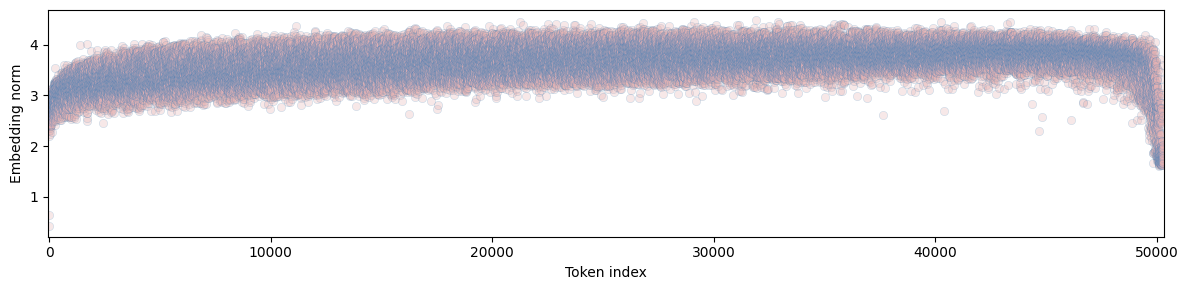

In [ ]:

plt.figure(figsize=(12,3))
plt.plot(np.squeeze(vectorNorms),'o',markeredgewidth=.3,markerfacecolor=[.9,.7,.7,.3])
plt.gca().set(xlabel='Token index',ylabel='Embedding norm',
              xlim=[-50,len(vectorNorms)+50])

plt.tight_layout()
plt.show()

In [ ]:
np.linalg.norm(embeddings_norm[300]), np.linalg.norm(embeddings[300])

(np.float32(1.0), np.float32(2.7873235))

# Part 2: Create a semantic axis

## Task_1:
- Tokenize the words “ future” and “ past” (note the preceding
spaces) and confirm that they are single-token words.
Create two semantic axis vectors: (1) subtract the two non
normed embeddings vectors and then unit-normalize the difference
vector; and (2) subtract the normed vectors.
Compare the norms of the two semantic axis vectors by print
ing their vector norms and visualizing them as in Figure 3.27.

In [9]:

# pick two words to define the axis
word4pos = tokenizer.encode(' future',add_special_tokens=False)
word4neg = tokenizer.encode(' past',add_special_tokens=False)

# confirm they're single-token words
print(word4pos, word4neg)

# but it's best to "de-dimensionalize" them for subsequent plotting
word4pos = word4pos[0]
word4neg = word4neg[0]

[499] [375]


In [12]:
# get the vectors for those words
v2add = embeddings[word4pos]
v2sub = embeddings[word4neg]

# create the "semantic axis" with "raw" vectors
semantic_axis = v2add - v2sub
semantic_axis /= np.linalg.norm(semantic_axis) # post-subtraction normalization

# now starting from the normed vectors
v2add = embeddings_norm[word4pos]
v2sub = embeddings_norm[word4neg]
semantic_axis_from_norm = v2add - v2sub

# print the norms
print(f'Norm of non-normed subtraction: {np.linalg.norm(semantic_axis):.3f}')
print(f'Norm of pre-normed subtraction: {np.linalg.norm(semantic_axis_from_norm):.3f}')

Norm of non-normed subtraction: 1.000
Norm of pre-normed subtraction: 1.183


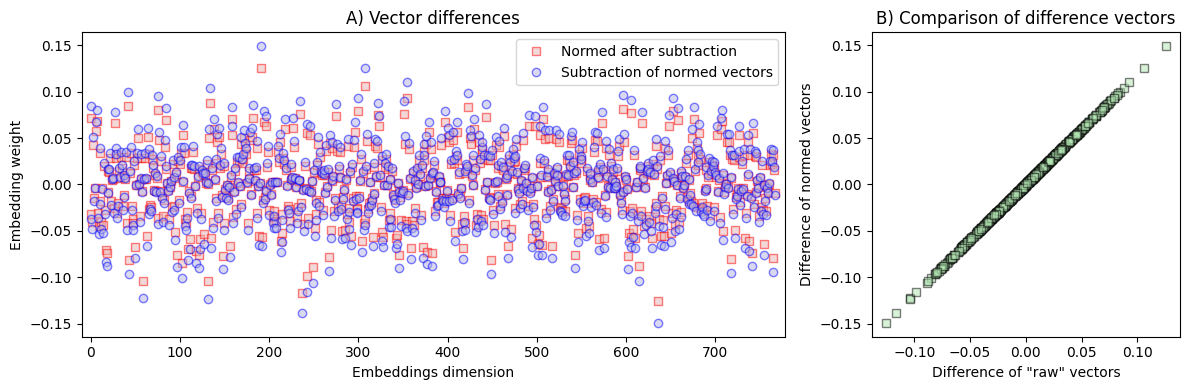

In [14]:
# visualize
fig = plt.figure(figsize=(12,4))
gs = gridspec.GridSpec(1,3,figure=fig)
ax1 = fig.add_subplot(gs[:-1])
ax2 = fig.add_subplot(gs[-1])


ax1.plot(semantic_axis,'rs',markerfacecolor=[.9,.7,.7,.5],label='Normed after subtraction')
ax1.plot(semantic_axis_from_norm,'bo',markerfacecolor=[.7,.7,.9,.5],label='Subtraction of normed vectors')
ax1.legend()
ax1.set(xlabel='Embeddings dimension',ylabel='Embedding weight',
        xlim=[-10,len(semantic_axis)+10],title='A) Vector differences')

ax2.plot(semantic_axis,semantic_axis_from_norm,'ks',markerfacecolor=[.7,.9,.7,.5])
ax2.set(xlabel='Difference of "raw" vectors',ylabel='Difference of normed vectors',
        title='B) Comparison of difference vectors')

plt.tight_layout()
plt.show()

In [15]:

print('Norms of the two vectors:')
print(f' {np.linalg.norm(embeddings[word4pos]):.3f}')
print(f' {np.linalg.norm(embeddings[word4neg]):.3f}')

Norms of the two vectors:
 3.219
 3.234


# Part 3: Project all tokens onto the axis


## Task_1:
- Calculate the vector-matrix product vE⊤, where v is the semantic
axis vector and E is the embeddings matrix. Visualize the dot
product results as well as their histogram, as in Figure 3.28.
Find the 10 vectors with the most positive dot products, and
the 10 most negative dot products, and print their dot products
and tokens as in the tables as below. These are the tokens that
maximally project onto the positive and negative “poles” of the
semantic axis
